> ### AI Lab (Post-lab Report)

# Lab \#8: XGBoost vs. MLP for Semiconductor Fault Classification
## Maximize Macro-F1 with Either Model on SECOM

<h4>
<div style="text-align: right">Due date: November 12, 2026, 2:00 PM (KST).</div><br>
<div style="text-align: right">Please upload [AILAB_w8_ID_Name.ipynb] to ONLINE CLASSROOM.</div><br>
<div style="text-align: right">For <b>Name</b>, using the team leader's name is recommended.</div>
</h4>

### Team Members

**Please write your student ID and name below.**

<h2><span style="color:white">
[2022440076] [안현진]<br>
[2022440103] [이정훈]<br>
[2023440085] [이광석]<br>
[2024440046] [나경미]
</span></h2>

<details>
<summary><b>📌 Instructions / Submission (CLICK!)</b></summary>

<h3>Instructions</h3>
<ul>
<li>Train and compare <b>both XGBoost and a PyTorch MLP</b> on SECOM. Choose <b>either one</b> for the final model; either family is equally acceptable. The optimization target is <b>Validation Macro-F1 (higher is better)</b>, rather than Accuracy.</li>
<li>Train and compare XGBoost and MLP. Choose your experiments freely; no prescribed experiment types or minimum experiment counts apply.</li>
<li><b>All model and training changes are allowed, including loss functions</b>, architectures within the MLP family, XGBoost objectives, preprocessing, sampling, optimizers, schedules, regularization, seeds, epoch counts, and decision thresholds. The final predictor must be one XGBoost or one MLP, rather than an ensemble across the two families. Retain the fixed split, label mapping, and evaluation definitions. <b>Do not retrain on Train + Validation or use Validation/Test examples in parameter updates.</b></li>
<li>Use training data to fit preprocessing and models. Select every setting, including the threshold, using validation data only. Evaluate the test set once after freezing the choices.</li>
<li>Complete the experiments and Results Report in your own words. The supplied code runs as a starting point; running it unchanged does not complete the experimental task.</li>
</ul>
<h3>Submission</h3>
<p>Submit one executed <code>AILAB_w8_ID_Name.ipynb</code> including XGBoost/MLP results, a description of your chosen experiments, final test results, confusion matrices, and the completed Results Report. Keep <code>SECOM_final_model.joblib</code> and the experiment CSV for verification. The deadline and grading follow the course announcement.</p>
</details>

<details>
<summary><b>📌 안내사항 / 제출 (CLICK!, 위와 같은 내용)</b></summary>

<h3>안내사항</h3>
<ul>
<li>SECOM에서 <b>XGBoost와 PyTorch MLP를 모두 학습하고 성능을 비교</b>합니다. 최종 모델은 <b>둘 중 어느 하나를 사용해도 동일하게 인정</b>하며, 특정 모델 사용에 따른 우대는 없습니다. 실험 목표는 Accuracy가 아니라 <b>Validation Macro-F1 최대화</b>입니다.</li>
<li>XGBoost와 MLP를 학습하고 성능을 비교하세요. 구체적인 실험 방법과 횟수는 자유이며, 정해진 필수 비교 항목이나 최소 실험 횟수는 없습니다.</li>
<li><b>Loss 변경을 포함한 모든 모델·학습 방식 변경을 허용합니다.</b> MLP 구조, XGBoost 학습 목적함수, 전처리, 샘플링, Optimizer, Scheduler, 정규화, 학습 시드, Epoch 수, 임계값 등을 자유롭게 변경하세요. 단, 최종 예측기는 XGBoost 또는 MLP 하나이며 두 계열을 결합한 앙상블은 사용하지 않습니다. 고정 분할·라벨·평가 지표를 유지하고, <b>Train+Validation 재학습 및 Validation/Test 샘플을 이용한 파라미터 업데이트는 금지</b>합니다.</li>
<li>전처리와 모델은 Train에서만 학습하고, 임계값을 포함한 모든 설정은 Validation으로 선택합니다. 설정을 확정한 뒤 Test를 한 번 평가하세요.</li>
<li>예제 코드는 실행 가능한 시작점입니다. 그대로 실행하는 데서 끝내지 말고 직접 실험을 추가하고 결과보고서를 작성하세요.</li>
</ul>
<h3>제출</h3>
<p>XGBoost·MLP 성능 비교, 자유롭게 수행한 실험 설명, 최종 Test 결과, 혼동행렬 및 결과보고서를 포함한 <code>AILAB_w8_ID_Name.ipynb</code> 하나를 제출하세요. 검증을 위해 <code>SECOM_final_model.joblib</code>와 실험 CSV를 보관하세요. 마감일과 배점은 수업 공지를 따릅니다.</p>
</details>

<details>
<summary><b>📋 Fixed Evaluation Protocol / 고정 평가 규칙 (CLICK!)</b></summary>

- Labels: original **−1 (pass) → 0**, original **+1 (fail) → 1**. Fail is the positive class.
- Fixed stratified **Train : Validation : Test ≈ 70 : 10 : 20**, split seed **42**. Integer rounding determines exact sizes.
- Do not remove or resample validation/test rows. If you add resampling, apply it only inside training data (and each training fold for cross-validation).
- Fit feature filtering, imputation, scaling, or feature selection on Train only. Never use test scores to select settings, seeds, or thresholds.
- Main score: `f1_score(..., labels=[0, 1], average="macro", zero_division=0)`.
- Also display Accuracy, Balanced Accuracy, Fail Precision/Recall/F1, and Average Precision (AP).
- Threshold predictions use **`probability >= threshold`**. If you choose to tune a threshold, use validation data and preserve it for Test. Threshold tuning is optional.
- Final models remain fitted on the **70% Train split**. This notebook does not refit on Train + Validation, because refitting can change the score scale and invalidate a selected threshold.
- Test results are for final reporting only. A local notebook cannot prevent students from inspecting test labels; this is a course protocol, not a hidden test server.

**한국어:** 분할·라벨·평가 지표를 유지하세요. 결측치 처리와 특징 선택은 Train에서만 학습하며, Validation/Test의 실제 클래스 비율을 유지합니다. 모델과 임계값은 Validation Macro-F1으로 확정하고 Test 결과를 보고 다시 조정하지 마세요. 이 실습에서는 재학습 없이 Train에서 학습한 모델을 그대로 최종 평가합니다.
</details>

**Model choice and freedom / 모델 선택 및 변경 범위:** Train and compare both families. The final goal is the highest Validation Macro-F1 achievable with **either XGBoost or MLP**. Loss changes and all other training/model changes are allowed within these families. Validation may select hyperparameters, epochs/checkpoints, thresholds, and model family, but must never be included in training updates. **No Train+Validation refit**, even after selection. Test remains final evaluation only. / 두 모델을 모두 비교한 후 어느 하나를 선택합니다. Loss를 포함한 모든 변경을 허용하지만 Validation을 합쳐 재학습할 수는 없습니다.

In [1]:
import datetime
print("This code is written at " + str(datetime.datetime.now()))

This code is written at 2026-11-12 02:51:01.067462


## 1. Introduction: XGBoost, MLP, and Imbalanced Classification

SECOM contains semiconductor process measurements, missing sensor values, and pass/fail labels. Failures are rare. We use the sensor matrix only; timestamps in the label file are excluded. This exercise uses a random stratified split, so it does not measure generalization to future production periods.

### 1.1 Gradient-boosted trees

XGBoost adds decision trees sequentially to reduce a regularized objective:

$$F_M(x)=\sum_{m=1}^{M} f_m(x),\qquad p(y=1\mid x)=\sigma(F_M(x)).$$

The binary logistic objective learns scores; **Macro-F1 is the model-selection target**, not the differentiable training loss. Increasing the positive-class weight changes the training loss; changing the threshold changes the final decision rule.

| Setting | Role |
|:--|:--|
| `n_estimators`, `learning_rate` | Number of trees and update size |
| `max_depth`, `min_child_weight` | Tree complexity |
| `subsample`, `colsample_bytree` | Row/feature sampling |
| `reg_alpha`, `reg_lambda` | Regularization |
| `scale_pos_weight` | Weight of positive (fail) examples |
| Decision threshold | Trade-off between missed failures and false alarms |

Trees do not require standardization here. XGBoost can handle `NaN` directly; the provided helpers also support mean/median imputation from `제조데이터.ipynb`. These are available options, not required comparisons.

### 1.2 Multilayer Perceptron (MLP)
An MLP maps standardized sensor vectors through fully connected hidden layers with nonlinear activations to a single fail logit. The supplied PyTorch baseline uses `BCEWithLogitsLoss`; `pos_weight` can increase the contribution of failures. Sigmoid converts logits to scores for thresholding. Dropout and weight decay help control overfitting.

For MLP, impute missing values and fit a `StandardScaler` on Train only. Use the same fitted transformations on Validation and Test. Unlike the tree baseline, this MLP requires finite inputs. You may change the architecture, loss (for example weighted BCE or focal loss), optimizer, batch size, learning rate, epoch count, checkpoint selection, and other training choices. Selection always uses Validation; updates always use Train.

### 1.3 Why Accuracy alone is insufficient

For fail as the positive class:

$$\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
P=\frac{TP}{TP+FP},\quad R=\frac{TP}{TP+FN},\quad F1=\frac{2PR}{P+R}.$$

$$\mathrm{Macro\!\! -\!\! F1}=\frac{F1_{pass}+F1_{fail}}{2},\qquad
\mathrm{Balanced\ Accuracy}=\frac{Recall_{pass}+Recall_{fail}}{2}.$$

- **Accuracy** gives every sample equal weight; the majority class dominates the total.
- **Macro-F1** gives the two class-specific F1 values equal weight. **Maximize this score on Validation.** It still depends on errors and class prevalence; always inspect fail recall too.
- **Fail Recall** measures how many true failures are detected. **Fail Precision** measures how often a failure alarm is correct.
- **Average Precision (AP)** summarizes the precision–recall ranking from continuous scores. It is supplementary here; it is not Macro-F1 and is not the trapezoidal PR-AUC.

**생각해 보기:** 모두 정상으로 예측하면 Accuracy는 높을 수 있지만, 불량 Recall과 F1은 0입니다. Macro-F1도 0이 되는지 직접 확인하세요. False Negative(불량 누락)와 False Positive(정상 오탐)의 현장 비용은 어떻게 다를까요?

## 2. Environment and SECOM Dataset

Run in Jupyter or Google Colab. A CPU is sufficient. The install cell uses compatible package ranges; the next cell prints exact versions for reproducibility.

In [2]:
%pip -q install "numpy==2.5.3" "pandas==2.3.3" "scipy==1.18.1" "scikit-learn==1.9.1" "xgboost==3.4.1" "joblib==1.6.0" "matplotlib>=3.7,<4" "torch>=2,<3"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"

from pathlib import Path
import copy
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
import joblib
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, average_precision_score,
    ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits

SPLIT_SEED = 42  # FIXED
TRAIN_SEED = 42
DATA_ROOT = Path("dataset/secom")
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("numpy", np.__version__, "pandas", pd.__version__)
print("sklearn", sklearn.__version__, "xgboost", xgboost.__version__, "torch", torch.__version__)

numpy 2.5.3 pandas 2.3.3
sklearn 1.9.1 xgboost 3.4.1 torch 2.15.0+cpu


### 2.1 Download and load the original data

Download the original UCI ZIP if local files are absent. Alternatively, place `secom.data` and `secom_labels.data` in `dataset/secom/`. The raw sensor matrix has **590 columns**; some UCI descriptions report 591 features. Inspect the actual shape printed below. No timestamp is used as a sensor feature.

In [4]:
# PROVIDED DATA LOADER
DATA_URL = "https://archive.ics.uci.edu/static/public/179/secom.zip"
required_files = ["secom.data", "secom_labels.data"]
if not all((DATA_ROOT / name).exists() for name in required_files):
    try:
        request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=120) as response:
            payload = response.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            for name in required_files:
                member = next(m for m in archive.namelist() if m.split("/")[-1] == name)
                (DATA_ROOT / name).write_bytes(archive.read(member))
    except Exception as exc:
        raise RuntimeError(f"Download failed. Put both SECOM files in {DATA_ROOT.resolve()}.") from exc

X = pd.read_csv(DATA_ROOT / "secom.data", sep=r"\s+", header=None)
raw_labels = pd.read_csv(DATA_ROOT / "secom_labels.data", sep=r"\s+", header=None)
assert len(X) == len(raw_labels) == 1567
assert set(raw_labels[0].unique()) == {-1, 1}
y = raw_labels[0].map({-1: 0, 1: 1}).astype(int)
X.columns = [f"sensor_{i:03d}" for i in range(X.shape[1])]
print("Sensor matrix:", X.shape, "| Label mapping: -1 -> 0 (pass), +1 -> 1 (fail)")

Sensor matrix: (1567, 590) | Label mapping: -1 -> 0 (pass), +1 -> 1 (fail)


### 2.2 Fixed split — BEFORE fitting any preprocessing

Use the same row split for all experiments. The second split takes 1/8 of the remaining 80% for Validation, giving approximately 70/10/20 overall. Examine class counts and missing values on Train. Leave Test features and labels unused until Section 5.

Split sizes: {'Train': 1096, 'Validation': 157, 'Test': 314}


,Train,Validation
Pass (0),1023,147
Fail (1),73,10


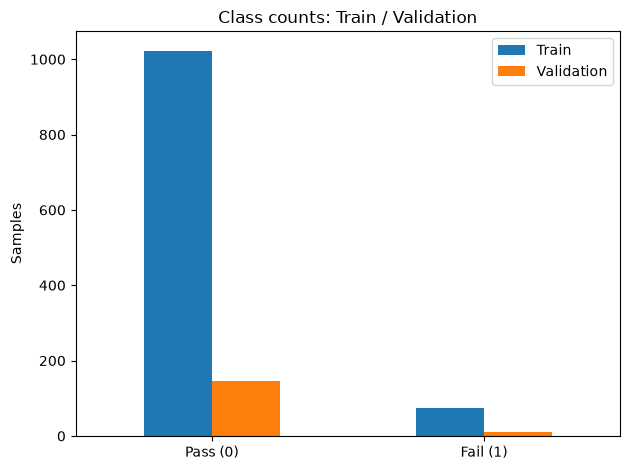

,Train missing (%)
sensor_157,90.602190
sensor_292,90.602190
sensor_293,90.602190
sensor_158,90.602190
sensor_492,86.313869
sensor_358,86.313869
sensor_220,86.313869
sensor_085,86.313869
sensor_517,66.149635
sensor_518,66.149635


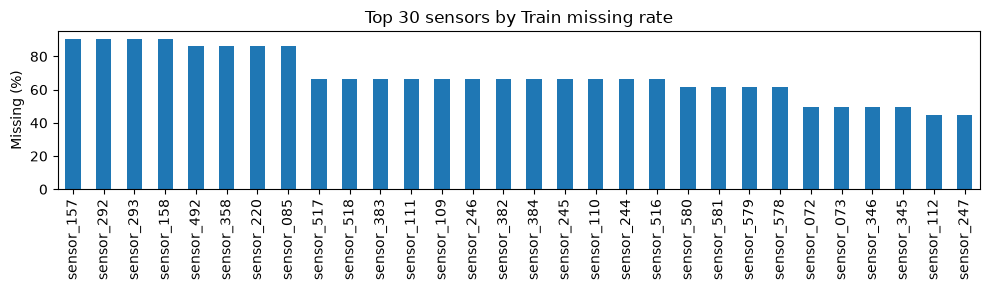

Train fail ratio: 0.0666058394160584


In [5]:
# FIXED SPLIT — DO NOT MODIFY
all_idx = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, stratify=y, random_state=SPLIT_SEED)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.125, stratify=y.iloc[trainval_idx], random_state=SPLIT_SEED)
X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
X_val, y_val = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
print("Split sizes:", {"Train": len(train_idx), "Validation": len(val_idx), "Test": len(test_idx)})
counts = pd.DataFrame({"Train": y_train.value_counts(), "Validation": y_val.value_counts()})
counts.index = ["Pass (0)" if i == 0 else "Fail (1)" for i in counts.index]
display(counts)
counts.plot.bar(rot=0, title="Class counts: Train / Validation")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()
missing_pct = X_train.isna().mean().sort_values(ascending=False) * 100
display(missing_pct.head(20).rename("Train missing (%)").to_frame())
missing_pct.head(30).plot.bar(figsize=(10, 3), title="Top 30 sensors by Train missing rate")
plt.ylabel("Missing (%)")
plt.tight_layout()
plt.show()
print("Train fail ratio:", y_train.mean())

## 3. Baselines and Reusable Evaluation

The supplied helpers retain feature names, drop all-missing/constant columns using Train only, and optionally fit a mean/median imputer on Train. Native mode retains `NaN` for XGBoost. Keep metric definitions unchanged.

Both baselines use the same Train/Validation rows. MLP additionally fits imputation and standardization on Train. The model-neutral prediction helper supports either final family.

In [6]:
# PROVIDED METRICS — DO NOT CHANGE
MAIN_METRIC = "Macro-F1"
def evaluate_scores(y_true, probabilities, threshold=0.5):
    probabilities = np.asarray(probabilities)
    assert probabilities.shape == (len(y_true),)
    assert np.isfinite(probabilities).all()
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro-F1": f1_score(y_true, predictions, labels=[0, 1], average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Fail Precision": precision_score(y_true, predictions, zero_division=0),
        "Fail Recall": recall_score(y_true, predictions, zero_division=0),
        "Fail F1": f1_score(y_true, predictions, zero_division=0),
        "AP": average_precision_score(y_true, probabilities),
    }

def fit_preprocessor(X_fit, mode):
    if mode not in {"native", "mean", "median"}:
        raise ValueError("mode must be native, mean, or median")
    columns = X_fit.columns[X_fit.nunique(dropna=True) > 1].tolist()
    assert columns, "No usable training features."
    imputer = None
    if mode != "native":
        imputer = SimpleImputer(strategy=mode)
        imputer.fit(X_fit[columns])
    return {"mode": mode, "columns": columns, "imputer": imputer}

def transform_features(X_input, preprocessing):
    values = X_input[preprocessing["columns"]]
    if preprocessing["imputer"] is not None:
        values = preprocessing["imputer"].transform(values)
    return np.asarray(values, dtype=np.float32)

BASE_PARAMS = dict(
    objective="binary:logistic", booster="gbtree", tree_method="hist",
    eval_metric="logloss", n_estimators=150, learning_rate=0.05,
    max_depth=3, min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.0, reg_lambda=1.0, scale_pos_weight=1.0,
    random_state=TRAIN_SEED, n_jobs=2,
)

def train_candidate(mode, overrides):
    preprocessing = fit_preprocessor(X_train, mode)
    params = {**BASE_PARAMS, **overrides}
    model = XGBClassifier(**params)
    model.fit(transform_features(X_train, preprocessing), y_train)
    val_prob = model.predict_proba(transform_features(X_val, preprocessing))[:, 1]
    return {"model": model, "preprocessing": preprocessing, "params": params,
            "mode": mode, "val_prob": val_prob, "family": "XGBoost"}

# EDITABLE MLP TRAINING — loss, architecture, and training strategy may be changed.
MLP_BASE_PARAMS = dict(hidden_sizes=(128, 64), dropout=0.3, epochs=60,
    batch_size=64, learning_rate=1e-3, weight_decay=1e-4,
    pos_weight=1.0, seed=TRAIN_SEED, loss="bce", focal_gamma=2.0)

def make_mlp(input_dim, params):
    layers = []
    for width in params["hidden_sizes"]:
        layers += [nn.Linear(input_dim, width), nn.ReLU(), nn.Dropout(params["dropout"])]
        input_dim = width
    return nn.Sequential(*layers, nn.Linear(input_dim, 1))

def mlp_loss(logits, targets, params):
    # Replace this function freely with another suitable binary classification loss.
    if params["loss"] == "bce":
        return nn.functional.binary_cross_entropy_with_logits(logits, targets,
            pos_weight=logits.new_tensor(params["pos_weight"]))
    if params["loss"] == "focal":
        bce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        prob = torch.sigmoid(logits)
        pt = torch.where(targets == 1, prob, 1 - prob)
        weights = torch.where(targets == 1, params["pos_weight"], 1.0)
        return (weights * (1 - pt).pow(params["focal_gamma"]) * bce).mean()
    raise ValueError("Implement your custom loss here or use bce/focal.")

def train_mlp(mode="median", overrides=None):
    params = {**MLP_BASE_PARAMS, **(overrides or {})}
    torch.manual_seed(params["seed"])
    # CPU baseline; device selection is editable. A small thread count suits this dataset.
    torch.set_num_threads(2)
    preprocessing = fit_preprocessor(X_train, mode)
    assert mode in {"mean", "median"}, "MLP requires finite inputs; impute first."
    train_array = transform_features(X_train, preprocessing)
    val_array = transform_features(X_val, preprocessing)
    scaler = StandardScaler().fit(train_array)
    preprocessing["scaler"] = scaler
    tx = torch.tensor(scaler.transform(train_array), dtype=torch.float32)
    vx = torch.tensor(scaler.transform(val_array), dtype=torch.float32)
    ty = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
    assert torch.isfinite(tx).all() and torch.isfinite(vx).all()
    loader = DataLoader(TensorDataset(tx, ty), batch_size=params["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(params["seed"]))
    model = make_mlp(tx.shape[1], params)
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["learning_rate"],
                                 weight_decay=params["weight_decay"])
    history, best_score, best_state, best_epoch = [], -1.0, None, None
    for epoch in range(params["epochs"]):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = mlp_loss(model(xb).squeeze(1), yb, params)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
        model.eval()
        with torch.no_grad():
            val_prob = torch.sigmoid(model(vx).squeeze(1)).numpy()
        # Baseline checkpoint selection: Validation Macro-F1 at threshold 0.5.
        # You may change checkpoint selection, but never use Test for selection.
        score = evaluate_scores(y_val, val_prob)[MAIN_METRIC]
        history.append({"Epoch": epoch + 1, "Train loss": total_loss / len(ty),
                        "Validation Macro-F1 @0.5": score})
        if score > best_score:
            best_score, best_epoch = score, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_prob = torch.sigmoid(model(vx).squeeze(1)).numpy()
    return {"model": model, "preprocessing": preprocessing, "params": params,
            "mode": mode, "family": "MLP", "val_prob": val_prob,
            "history": history, "best_epoch": best_epoch}

def predict_candidate(candidate, X_input):
    if candidate["mode"] == "focal_pca":
        with threadpool_limits(limits=2):
            values = candidate["preprocessing"]["pipeline"].transform(X_input.reset_index(drop=True))
            return candidate["model"].predict_proba(values)[:, 1]
    values = transform_features(X_input, candidate["preprocessing"])
    if candidate["family"] == "XGBoost":
        return candidate["model"].predict_proba(values)[:, 1]
    values = candidate["preprocessing"]["scaler"].transform(values)
    candidate["model"].eval()
    with torch.no_grad():
        return torch.sigmoid(candidate["model"](
            torch.tensor(values, dtype=torch.float32)).squeeze(1)).cpu().numpy()


,Accuracy,Macro-F1,Balanced Accuracy,Fail Precision,Fail Recall,Fail F1,AP
Model,,,,,,,
All-pass,0.9363,0.4836,0.5000,0.0,0.0,0.0,0.0637
XGBoost baseline,0.9363,0.4836,0.5000,0.0,0.0,0.0,0.2670
MLP baseline,0.9427,0.6849,0.6432,0.6,0.3,0.4,0.3375


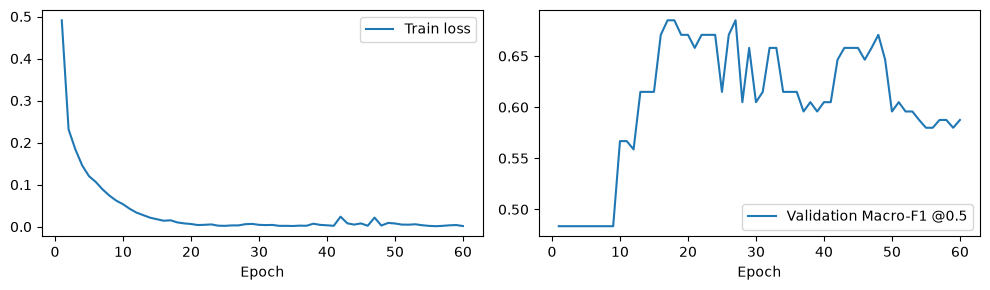

MLP baseline selected epoch: 17
All-pass Accuracy can be high even though Fail Recall is zero.


In [7]:
# BOTH MODEL BASELINES — same splits and threshold 0.5
all_pass_val = np.zeros(len(y_val))
baseline = train_candidate("native", {"scale_pos_weight": 1.0})
mlp_baseline = train_mlp("median", {"pos_weight": 1.0})
validation_baselines = pd.DataFrame([
    {"Model": "All-pass", **evaluate_scores(y_val, all_pass_val)},
    {"Model": "XGBoost baseline", **evaluate_scores(y_val, baseline["val_prob"])},
    {"Model": "MLP baseline", **evaluate_scores(y_val, mlp_baseline["val_prob"])},
]).set_index("Model")
display(validation_baselines.round(4))
history = pd.DataFrame(mlp_baseline["history"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history.plot(x="Epoch", y="Train loss", ax=axes[0])
history.plot(x="Epoch", y="Validation Macro-F1 @0.5", ax=axes[1])
plt.tight_layout()
plt.show()
print("MLP baseline selected epoch:", mlp_baseline["best_epoch"])
print("All-pass Accuracy can be high even though Fail Recall is zero.")

## 4. Freely Improve Macro-F1 / 자유 실험

Train and compare **both XGBoost and MLP**, then use **either model** to maximize **Validation Macro-F1**. Either family is equally acceptable.

**Loss functions and all other model/training choices may be changed freely.** There are no prescribed preprocessing comparisons, class-weight settings, hyperparameter experiments, threshold comparisons, or minimum experiment counts. Choose and explain your own approach.

Use Train for fitting and Validation for selection. **Do not retrain with Validation included.** Keep the evaluation split, label mapping, and metric definitions unchanged; use Test only for final evaluation.

**XGBoost와 MLP를 모두 학습하고 비교한 후, 둘 중 어느 모델이든 사용하여 Validation Macro-F1을 최대화하세요. Loss 변경을 포함한 모든 모델·학습 방식 변경을 허용합니다. 실험 방법과 횟수는 자유입니다. 특정 전처리·가중치·하이퍼파라미터·임계값 비교를 필수로 수행할 필요는 없습니다. 단, Validation을 포함한 재학습은 금지하며 Test는 최종 평가에만 사용합니다.**

The code below is an editable convenience scaffold, not a required experimental procedure. You may edit or replace the experiment/training code. The default compares the two supplied baselines without an additional parameter search. Threshold tuning is off by default and is entirely optional.

아래 코드는 수정·교체 가능한 실행 예제입니다. 추가 실험 목록은 비어 있으며, 자동 임계값 탐색도 기본적으로 수행하지 않습니다.

### 4.1 Focal XGBoost 재현

팀 내부 선행 탐색 실험에서 Validation 기준으로 가장 성능이 높았던 후보 `focal:19811:300`을 Train에서 학습한다.
Pearson 상관 필터링(0.85), 클래스별 bootstrap 20회의 F 통계량 순위로 선택한 센서 50개, 중앙값 대치, PCA 성분 8개와 결측 표시 50개를 사용한다. 가중 Focal 목적함수, 학습 시드 24142, 트리 300개와 고정 임계값 0.6851693987846375를 적용한다.
원본과 예측이 일치한 환경은 Linux의 Python 3.14.7과 2절의 고정 패키지 버전이다. 다음 코드 셀은 학습 및 저장 모델에 필요한 전처리 모듈을 생성한다.

선행 탐색 실험의 주요 Validation 기록은 아래 표(`historical_experiments`)에 요약하였으며, 이번 실행의 MLP는 3절에서 학습한 과제 기본 모델을 비교 기준으로 사용한다.


In [8]:
%%writefile secom_final_runtime.py
# Frozen Train-only preprocessing and Focal objective; copied from the study.
# No search, no cross-validation, no Test fitting.
import copy
import warnings
import numpy as np
from scipy.special import expit
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

class FeaturePipeline:
    def __init__(self, spec):
        self.spec = dict(spec)

    def fit(self, x, y):
        self.columns = x.columns[x.nunique(dropna=True) > 1].tolist()
        if not self.columns:
            raise ValueError("No nonconstant Train features")
        raw = x[self.columns].to_numpy(dtype=np.float32)
        self.imputer = SimpleImputer(strategy="median").fit(raw)
        finite = self.imputer.transform(raw).astype(np.float32)
        keep = np.arange(len(self.columns))
        correlation = self.spec.get("correlation")
        if correlation is not None:
            with np.errstate(invalid="ignore", divide="ignore"):
                matrix = np.abs(np.corrcoef(finite, rowvar=False))
            matrix = np.nan_to_num(matrix, nan=0.0)
            selected = []
            for index in keep:
                if not selected or np.max(matrix[index, selected]) < correlation:
                    selected.append(int(index))
            keep = np.asarray(selected)
        ranking = self.spec["selector"]
        if ranking == "none":
            scores = np.ones(len(keep))
        elif ranking == "f":
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                scores = f_classif(finite[:, keep], y)[0]
        elif ranking == "mi":
            scores = mutual_info_classif(finite[:, keep], y, random_state=42, n_neighbors=3)
        elif ranking == "l1":
            scale = StandardScaler().fit(finite[:, keep])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                estimator = LogisticRegression(penalty="l1", solver="liblinear", C=.1,
                    class_weight="balanced", max_iter=2000, random_state=42).fit(scale.transform(finite[:, keep]), y)
            scores = np.abs(estimator.coef_[0])
        else:
            raise ValueError(ranking)
        scores = np.nan_to_num(scores, nan=-1e30, posinf=1e30, neginf=-1e30)
        k = len(keep) if self.spec["k"] is None else min(int(self.spec["k"]), len(keep))
        self.selected = np.sort(keep[np.argsort(-scores, kind="stable")[:k]])
        values = finite[:, self.selected]
        self.mode = self.spec["mode"]
        components = self.spec.get("components", 16)
        if self.mode in ("pca", "pls"):
            self.scaler = StandardScaler().fit(values)
            standardized = self.scaler.transform(values)
            dimension = max(1, min(components, len(values) - 1, values.shape[1]))
            if self.mode == "pca":
                self.projector = PCA(dimension, svd_solver="randomized", random_state=42).fit(standardized)
            else:
                self.projector = PLSRegression(n_components=dimension, scale=False, max_iter=300).fit(standardized, y)
        elif self.mode in ("normal_z", "normal_pca"):
            normal = values[np.asarray(y) == 0]
            self.normal_mean = normal.mean(axis=0)
            self.normal_std = np.maximum(normal.std(axis=0), 1e-6)
            if self.mode == "normal_pca":
                dimension = max(1, min(components, len(normal) - 1, normal.shape[1]))
                self.projector = PCA(dimension, svd_solver="randomized", random_state=42).fit(
                    (normal - self.normal_mean) / self.normal_std)
        elif self.mode != "raw":
            raise ValueError(self.mode)
        self.training_rows = len(x)
        self.feature_names = [self.columns[i] for i in self.selected]
        return self

    def transform(self, x):
        raw = x[self.columns].to_numpy(dtype=np.float32)
        missing = np.isnan(raw[:, self.selected]).astype(np.float32)
        finite = self.imputer.transform(raw).astype(np.float32)[:, self.selected]
        if self.mode in ("pca", "pls"):
            output = self.projector.transform(self.scaler.transform(finite))
        else:
            output = raw[:, self.selected] if self.spec["missing"] == "native" else finite
            if self.mode in ("normal_z", "normal_pca"):
                z = np.clip((finite - self.normal_mean) / self.normal_std, -1000, 1000)
                absolute = np.abs(z)
                extra = [absolute.mean(axis=1), absolute.max(axis=1),
                         (absolute > 2).mean(axis=1), (absolute > 3).mean(axis=1),
                         np.quantile(absolute, .9, axis=1)]
                if self.mode == "normal_pca":
                    reconstructed = self.projector.inverse_transform(self.projector.transform(z))
                    extra.extend([np.square(z - reconstructed).mean(axis=1),
                                  np.abs(z - reconstructed).max(axis=1)])
                output = np.column_stack([output, *extra])
        if self.spec.get("indicators", False):
            output = np.column_stack([output, missing])
        output = np.asarray(output, dtype=np.float32)
        if np.isinf(output).any():
            raise ValueError("Infinite transformed feature")
        return output

    def fit_transform(self, x, y):
        return self.fit(x, y).transform(x)

class DiagnosticPipeline(FeaturePipeline):
    def __init__(self, spec):
        self.requested_spec = copy.deepcopy(spec)
        super().__init__(spec)

    def fit(self, x, y):
        requested = self.requested_spec
        if requested["selector"] != "stable_f":
            return super().fit(x, y)
        # Candidate filtering and bootstrap rankings both see fitting rows only.
        screening = dict(requested, mode="raw", selector="none", k=None,
                         missing="median", indicators=False)
        screen = FeaturePipeline(screening).fit(x, y)
        values = screen.transform(x)
        y = np.asarray(y)
        classes = [np.flatnonzero(y == label) for label in (0, 1)]
        rng = np.random.default_rng(20261106)
        k = min(int(requested["k"]), values.shape[1])
        votes = np.zeros(values.shape[1])
        rank_sum = np.zeros(values.shape[1])
        for _ in range(20):
            rows = np.concatenate([rng.choice(c, len(c), replace=True) for c in classes])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                scores = f_classif(values[rows], y[rows])[0]
            scores = np.nan_to_num(scores, nan=-1e30, posinf=1e30, neginf=-1e30)
            order = np.argsort(-scores, kind="stable")
            votes[order[:k]] += 1
            rank_sum[order] += np.arange(len(order))
        order = np.lexsort((np.arange(len(votes)), rank_sum, -votes))[:k]
        names = [screen.feature_names[i] for i in np.sort(order)]
        self.stability_votes = {screen.feature_names[i]: float(votes[i] / 20)
                                for i in order}
        self.spec = dict(requested, selector="none", k=None, correlation=None)
        return super().fit(x[names], y)

class NightPipeline(DiagnosticPipeline):
    def __init__(self, spec):
        self.input_spec = dict(spec)
        adapted = dict(spec)
        if adapted["mode"] == "robust_tail":
            adapted["mode"] = "raw"
        if adapted.get("correlation_method", "pearson") == "spearman":
            adapted["correlation"] = None
        super().__init__(adapted)

    def fit(self, x, y):
        incoming = x
        s = self.input_spec
        if s.get("correlation_method", "pearson") == "spearman" and s.get("correlation") is not None:
            names = x.columns[x.nunique(dropna=True) > 1].tolist()
            matrix = x[names].corr(method="spearman", min_periods=s.get("min_observed", 200)).abs().to_numpy()
            matrix = np.nan_to_num(matrix, nan=0.0)
            order = np.argsort(x[names].isna().sum().to_numpy(), kind="stable")
            keep = []
            for i in order:
                if not keep or np.max(matrix[i, keep]) < s["correlation"]:
                    keep.append(int(i))
            incoming = x[[names[i] for i in sorted(keep)]]
        super().fit(incoming, y)
        raw = x[self.columns].to_numpy(dtype=np.float64)[:, self.selected]
        finite = self.imputer.transform(x[self.columns].to_numpy(dtype=np.float32))[:, self.selected].astype(np.float64)
        self.robust_center = np.median(finite, axis=0)
        sd = finite.std(axis=0)
        iqr = np.quantile(finite, .75, axis=0) - np.quantile(finite, .25, axis=0)
        self.robust_scale = np.where(iqr > s.get("iqr_floor", .02) * sd, iqr, sd)
        self.robust_scale = np.maximum(self.robust_scale, 1e-6)
        self.tail_mean = np.nanmean(raw, axis=0)
        self.tail_sd = np.maximum(np.nanstd(raw, axis=0), 1e-6)
        self.class_centers = np.stack([np.median(finite[np.asarray(y) == c], axis=0) for c in [0, 1]])
        return self

    def transform(self, x):
        s = self.input_spec
        base = super().transform(x)
        raw = x[self.columns].to_numpy(dtype=np.float64)[:, self.selected]
        finite = self.imputer.transform(x[self.columns].to_numpy(dtype=np.float32))[:, self.selected].astype(np.float64)
        columns = len(self.selected)
        extras = []
        if s["mode"] == "robust_tail":
            u = (finite - self.robust_center) / self.robust_scale
            compression = s.get("compression", 4.5)
            compressed = u / np.sqrt(1 + (u / compression) ** 2)
            if s["missing"] == "native":
                compressed[np.isnan(raw)] = np.nan
            indicators = np.isnan(raw).astype(np.float32) if s.get("indicators", False) else np.empty((len(x), 0))
            base = np.column_stack([compressed, indicators])
            z = np.nan_to_num((raw - self.tail_mean) / self.tail_sd, nan=0.0)
            z = np.clip(z, -1e4, 1e4)
            cutoff = s.get("tail_cutoff", 5)
            extras += [np.log1p(np.maximum(z, 0).max(axis=1)),
                       np.log1p(np.maximum(-z, 0).max(axis=1)),
                       (z > cutoff).sum(axis=1) / columns,
                       (z < -cutoff).sum(axis=1) / columns]
        if s.get("class_distance", False):
            distances = []
            for center in self.class_centers:
                normalized = np.clip((finite - center) / self.robust_scale, -100, 100)
                distances.append(np.square(normalized).mean(axis=1))
                extras.append(np.abs(normalized).mean(axis=1))
                extras.append(np.log1p(distances[-1]))
            extras.append(np.log1p(distances[1]) - np.log1p(distances[0]))
        if s.get("missing_summary", False):
            extras += [x.isna().mean(axis=1).to_numpy(), np.isnan(raw).mean(axis=1)]
        result = np.asarray(np.column_stack([base, *extras]) if extras else base, dtype=np.float32)
        assert not np.isinf(result).any()
        return result

def weights(y, positive_weight):
    w = np.where(np.asarray(y) == 1, positive_weight, 1.0).astype(np.float64)
    return w / w.mean()

class FocalObjective:
    def __init__(self, gamma_positive=2.0, gamma_negative=2.0, positive_weight=1.0):
        self.gamma_positive = float(gamma_positive)
        self.gamma_negative = float(gamma_negative)
        self.positive_weight = float(positive_weight)

    def __call__(self, y_true, margin):
        y = np.asarray(y_true)
        margin = np.asarray(margin, dtype=np.float64)
        sign = 2 * y - 1
        gamma = np.where(y == 1, self.gamma_positive, self.gamma_negative)
        pt = expit(sign * margin)
        q = expit(-sign * margin)
        log_pt = -np.logaddexp(0, -sign * margin)
        w = weights(y, self.positive_weight)
        gradient = sign * w * q ** gamma * (gamma * pt * log_pt - q)
        # For gamma >= 0: true h <= w*(gamma+1)^2*pt*(1-pt)^(gamma+1).
        curvature = w * (gamma + 1) ** 2 * pt * q ** (gamma + 1)
        return gradient, np.maximum(curvature, 1e-8)

    def loss(self, y, margin):
        y = np.asarray(y)
        sign = 2 * y - 1
        gamma = np.where(y == 1, self.gamma_positive, self.gamma_negative)
        q = expit(-sign * margin)
        return float(np.sum(weights(y, self.positive_weight) * q ** gamma * np.logaddexp(0, -sign * margin)))


Writing secom_final_runtime.py


,Experiment,Family,Preprocessing,Parameters,Decision,Threshold,Accuracy,Macro-F1,Balanced Accuracy,Fail Precision,Fail Recall,Fail F1,AP
2,focal:19811:300,XGBoost,focal_pca,"{'features': {'mode': 'pca', 'selector': 'stab...",Selected threshold,0.6852,0.9745,0.8683,0.8000,1.0000,0.6,0.7500,0.6479
1,MLP baseline,MLP,median,"{'hidden_sizes': (128, 64), 'dropout': 0.3, 'e...",Selected threshold,0.5000,0.9427,0.6849,0.6432,0.6000,0.3,0.4000,0.3375
3,focal:19811:300,XGBoost,focal_pca,"{'features': {'mode': 'pca', 'selector': 'stab...",Default 0.5,0.5000,0.8280,0.6213,0.7684,0.2258,0.7,0.3415,0.6479
0,XGBoost baseline,XGBoost,native,"{'objective': 'binary:logistic', 'booster': 'g...",Selected threshold,0.5000,0.9363,0.4836,0.5000,0.0000,0.0,0.0000,0.2670


Selected: focal:19811:300 | Threshold: 0.6851693987846375
Validation Macro-F1: 0.8682885906040269


,Experiment,Threshold,Accuracy,Macro-F1,Balanced Accuracy,Fail Precision,Fail Recall,Fail F1,AP
Family,,,,,,,,,
XGBoost,focal:19811:300,0.6852,0.9745,0.8683,0.8000,1.0,0.6,0.75,0.6479
MLP,MLP baseline,0.5000,0.9427,0.6849,0.6432,0.6,0.3,0.40,0.3375


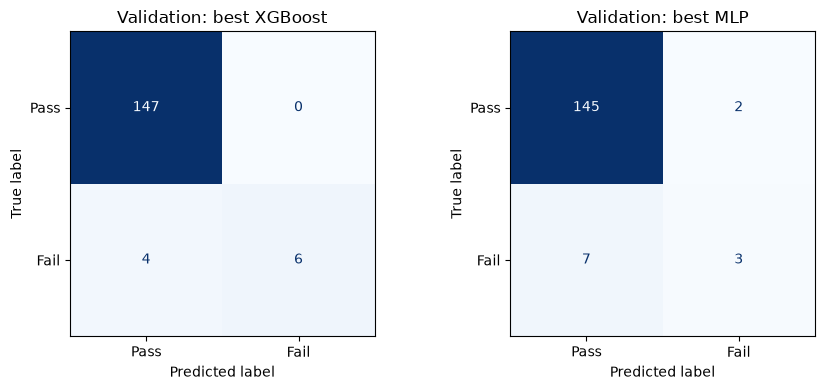

Final family selected by Validation Macro-F1: XGBoost


In [9]:
# EDITABLE EXPERIMENT SETTINGS
from secom_final_runtime import FocalObjective, NightPipeline

FOCAL_SPEC = {'features': {'mode': 'pca',
              'selector': 'stable_f',
              'k': 50,
              'missing': 'median',
              'indicators': True,
              'correlation': 0.85,
              'correlation_method': 'pearson',
              'min_observed': 200,
              'components': 8,
              'class_distance': False,
              'missing_summary': False,
              'iqr_floor': 0.02,
              'compression': 4.5,
              'tail_cutoff': 5.0},
 'model': {'booster': 'gbtree',
           'n_estimators': 300,
           'learning_rate': 0.05,
           'max_depth': 6,
           'grow_policy': 'depthwise',
           'max_leaves': 0,
           'min_child_weight': 4.374481830571974,
           'reg_lambda': 56.16803300327837,
           'reg_alpha': 0.1,
           'gamma': 0.0,
           'subsample': 0.9887300815835176,
           'colsample_bytree': 0.9106956063389577,
           'colsample_bylevel': 0.7288206480902055,
           'colsample_bynode': 0.8819642320924759,
           'max_bin': 512,
           'max_delta_step': 3,
           'base_score': 0.1,
           'tree_method': 'hist',
           'sampling_method': 'uniform'},
 'loss': {'kind': 'focal',
          'positive_weight': 14.775067522346903,
          'gamma_positive': 0.5,
          'gamma_negative': 0.5},
 'sampling': {'kind': 'none', 'ratio': 0.5},
 'seed': 24142}
FOCAL_THRESHOLD = 0.6851693987846375

with threadpool_limits(limits=2):
    pipeline = NightPipeline(FOCAL_SPEC["features"])
    train_features = pipeline.fit_transform(X_train.reset_index(drop=True), y_train.reset_index(drop=True))
    val_features = pipeline.transform(X_val.reset_index(drop=True))
    objective = FocalObjective(FOCAL_SPEC["loss"]["gamma_positive"],
        FOCAL_SPEC["loss"]["gamma_negative"], FOCAL_SPEC["loss"]["positive_weight"])
    model = XGBClassifier(**FOCAL_SPEC["model"], objective=objective,
                          n_jobs=2, random_state=FOCAL_SPEC["seed"], eval_metric="logloss")
    model.fit(train_features, y_train.reset_index(drop=True), verbose=False)
    val_prob = model.predict_proba(val_features)[:, 1]

candidates = [
    {**baseline, "name": "XGBoost baseline", "threshold": 0.5},
    {**mlp_baseline, "name": "MLP baseline", "threshold": 0.5},
    {"name": "focal:19811:300", "family": "XGBoost", "mode": "focal_pca",
     "model": model, "preprocessing": {"pipeline": pipeline}, "params": FOCAL_SPEC,
     "val_prob": val_prob, "threshold": FOCAL_THRESHOLD},
]

records = []
for candidate in candidates:
    threshold = candidate["threshold"]
    scores = evaluate_scores(y_val, candidate["val_prob"], threshold)
    candidate["selection_score"] = scores[MAIN_METRIC]
    candidate["threshold_table"] = pd.DataFrame([{"Threshold": threshold, **scores}])
    record = {"Experiment": candidate["name"], "Family": candidate["family"],
              "Preprocessing": candidate["mode"], "Parameters": str(candidate["params"])}
    records.append({**record, "Decision": "Selected threshold", "Threshold": threshold, **scores})
    if threshold != 0.5:
        records.append({**record, "Decision": "Default 0.5", "Threshold": 0.5,
                        **evaluate_scores(y_val, candidate["val_prob"])})
experiment_results = pd.DataFrame(records)
display(experiment_results.sort_values(MAIN_METRIC, ascending=False, kind="stable").round(4))
experiment_results.to_csv("SECOM_validation_experiments.csv", index=False)
best_candidate = max(candidates, key=lambda c: c["selection_score"])
print("Selected:", best_candidate["name"], "| Threshold:", best_candidate["threshold"])
print("Validation Macro-F1:", best_candidate["selection_score"])
# Compare the best validation-selected configuration from each model family.
best_by_family = {family: max((c for c in candidates if c["family"] == family),
    key=lambda c: c["selection_score"]) for family in ["XGBoost", "MLP"]}
family_comparison = pd.DataFrame([
    {"Family": family, "Experiment": candidate["name"], "Threshold": candidate["threshold"],
     **evaluate_scores(y_val, candidate["val_prob"], candidate["threshold"])}
    for family, candidate in best_by_family.items()
]).set_index("Family")
display(family_comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (family, candidate) in zip(axes, best_by_family.items()):
    ConfusionMatrixDisplay.from_predictions(y_val,
        (candidate["val_prob"] >= candidate["threshold"]).astype(int),
        labels=[0, 1], display_labels=["Pass", "Fail"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Validation: best {family}")
plt.tight_layout()
plt.show()
print("Final family selected by Validation Macro-F1:", best_candidate["family"])


In [10]:
historical_experiments = pd.DataFrame([{'Model': 'M1',
  'Change': '기존 상위권 기준 모델',
  'Threshold': 0.75,
  'Accuracy': 0.9617834394904459,
  'Macro-F1': 0.8024328859060403,
  'Balanced Accuracy': 0.7465986394557823,
  'Fail Precision': 0.8333333333333334,
  'Fail Recall': 0.5,
  'Fail F1': 0.625,
  'AP': 0.5005848055725352,
  'TN': 146,
  'FP': 1,
  'FN': 5,
  'TP': 5,
  'Evidence': 'historical XGBoost logs'},
 {'Model': 'M2',
  'Change': '가중치·분할 조건 조정',
  'Threshold': 0.8215807676315308,
  'Accuracy': 0.9681528662420382,
  'Macro-F1': 0.8249721293199554,
  'Balanced Accuracy': 0.75,
  'Fail Precision': 1.0,
  'Fail Recall': 0.5,
  'Fail F1': 0.6666666666666666,
  'AP': 0.5376646561445855,
  'TN': 147,
  'FP': 0,
  'FN': 5,
  'TP': 5,
  'Evidence': 'historical XGBoost logs'},
 {'Model': 'M3',
  'Change': '정상 기준 특징 추가',
  'Threshold': 0.8396018147468567,
  'Accuracy': 0.9681528662420382,
  'Macro-F1': 0.8249721293199554,
  'Balanced Accuracy': 0.75,
  'Fail Precision': 1.0,
  'Fail Recall': 0.5,
  'Fail F1': 0.6666666666666666,
  'AP': 0.5563238722680985,
  'TN': 147,
  'FP': 0,
  'FN': 5,
  'TP': 5,
  'Evidence': 'historical XGBoost logs'},
 {'Model': 'M4',
  'Change': '비대칭 Focal + 입력 재구성',
  'Threshold': 0.6147738099098206,
  'Accuracy': 0.9745222929936306,
  'Macro-F1': 0.8682885906040269,
  'Balanced Accuracy': 0.8,
  'Fail Precision': 1.0,
  'Fail Recall': 0.6,
  'Fail F1': 0.75,
  'AP': 0.6428979291370136,
  'TN': 147,
  'FP': 0,
  'FN': 4,
  'TP': 6,
  'Evidence': 'historical XGBoost logs'},
 {'Model': 'M5',
  'Change': '최종 Focal 모델 세부 조정',
  'Threshold': 0.6851693987846375,
  'Accuracy': 0.9745222929936306,
  'Macro-F1': 0.8682885906040269,
  'Balanced Accuracy': 0.8,
  'Fail Precision': 1.0,
  'Fail Recall': 0.6,
  'Fail F1': 0.75,
  'AP': 0.64790248424175,
  'TN': 147,
  'FP': 0,
  'FN': 4,
  'TP': 6,
  'Evidence': 'historical XGBoost logs'}])
display(historical_experiments.set_index('Model').round(6))

,Change,Threshold,Accuracy,Macro-F1,Balanced Accuracy,Fail Precision,Fail Recall,Fail F1,AP,TN,FP,FN,TP,Evidence
Model,,,,,,,,,,,,,,
M1,기존 상위권 기준 모델,0.750000,0.961783,0.802433,0.746599,0.833333,0.5,0.625000,0.500585,146,1,5,5,historical XGBoost logs
M2,가중치·분할 조건 조정,0.821581,0.968153,0.824972,0.750000,1.000000,0.5,0.666667,0.537665,147,0,5,5,historical XGBoost logs
M3,정상 기준 특징 추가,0.839602,0.968153,0.824972,0.750000,1.000000,0.5,0.666667,0.556324,147,0,5,5,historical XGBoost logs
M4,비대칭 Focal + 입력 재구성,0.614774,0.974522,0.868289,0.800000,1.000000,0.6,0.750000,0.642898,147,0,4,6,historical XGBoost logs
M5,최종 Focal 모델 세부 조정,0.685169,0.974522,0.868289,0.800000,1.000000,0.6,0.750000,0.647902,147,0,4,6,historical XGBoost logs


### 4.2 Optional visualization / 선택적 시각화

This supplied plot illustrates threshold behavior if you enable threshold search. With search disabled, it displays only the current threshold. Using or modifying this analysis is optional; it is not a required experiment.

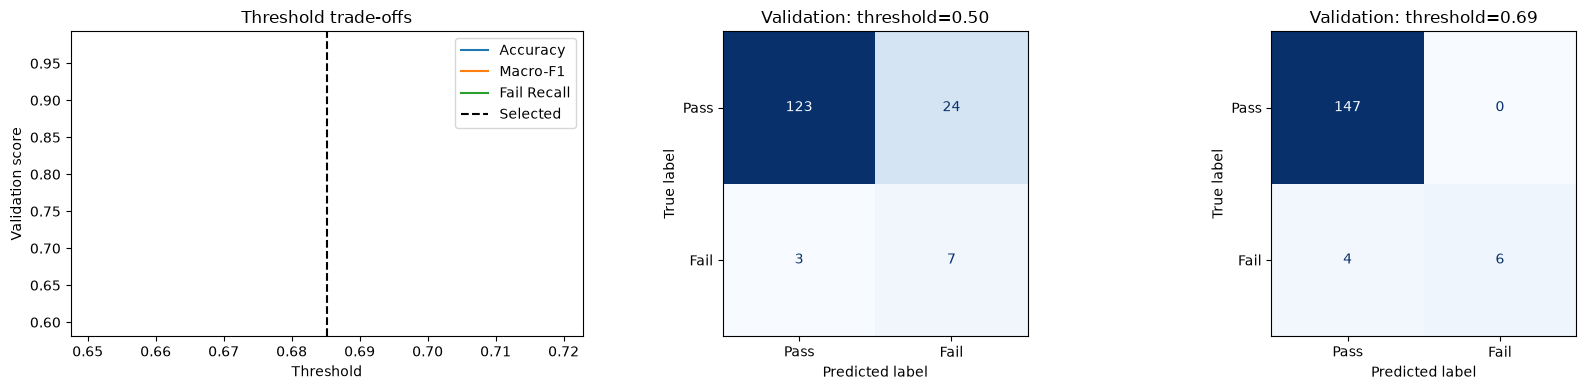

In [11]:
table = best_candidate["threshold_table"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for metric in ["Accuracy", "Macro-F1", "Fail Recall"]:
    axes[0].plot(table["Threshold"], table[metric], label=metric)
axes[0].axvline(best_candidate["threshold"], color="black", linestyle="--", label="Selected")
axes[0].set(xlabel="Threshold", ylabel="Validation score", title="Threshold trade-offs")
axes[0].legend()
for ax, threshold in zip(axes[1:], [0.5, best_candidate["threshold"]]):
    pred = (best_candidate["val_prob"] >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, labels=[0, 1], display_labels=["Pass", "Fail"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Validation: threshold={threshold:.2f}")
plt.tight_layout()
plt.show()

## 5. Final Test Evaluation — DO NOT MODIFY

Finish every experiment, then freeze the best XGBoost, best MLP, and overall selected candidate using **Validation Macro-F1 only**. Either model family is acceptable for the final submission. Do not retrain on Train + Validation.

The final cell compares All-pass, both original baselines at 0.5, the best validation-selected XGBoost and MLP at their own frozen thresholds, and the overall final model. It also displays the final model at 0.5 to isolate the effect of threshold selection. **The final score is the frozen overall model's Test Macro-F1, not whichever Test row looks best.**

The session guard avoids accidental repeats; it is not a security boundary. Never use Test results for further selection. Save preprocessing, weights, settings, split indices, and results for verification.

In [12]:
# FREEZE ALL CHOICES — no training on Validation, and no selection using Test.
final_bundle = copy.deepcopy(best_candidate)
frozen_by_family = copy.deepcopy(best_by_family)
frozen_baselines = {"XGBoost": copy.deepcopy(baseline), "MLP": copy.deepcopy(mlp_baseline)}
print("Frozen final family:", final_bundle["family"])
print("Frozen experiment:", final_bundle["name"])
print("Frozen threshold:", final_bundle["threshold"])
print("Frozen parameters:", final_bundle["params"])

Frozen final family: XGBoost
Frozen experiment: focal:19811:300
Frozen threshold: 0.6851693987846375
Frozen parameters: {'features': {'mode': 'pca', 'selector': 'stable_f', 'k': 50, 'missing': 'median', 'indicators': True, 'correlation': 0.85, 'correlation_method': 'pearson', 'min_observed': 200, 'components': 8, 'class_distance': False, 'missing_summary': False, 'iqr_floor': 0.02, 'compression': 4.5, 'tail_cutoff': 5.0}, 'model': {'booster': 'gbtree', 'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'grow_policy': 'depthwise', 'max_leaves': 0, 'min_child_weight': 4.374481830571974, 'reg_lambda': 56.16803300327837, 'reg_alpha': 0.1, 'gamma': 0.0, 'subsample': 0.9887300815835176, 'colsample_bytree': 0.9106956063389577, 'colsample_bylevel': 0.7288206480902055, 'colsample_bynode': 0.8819642320924759, 'max_bin': 512, 'max_delta_step': 3, 'base_score': 0.1, 'tree_method': 'hist', 'sampling_method': 'uniform'}, 'loss': {'kind': 'focal', 'positive_weight': 14.775067522346903, 'gamm

,Test class count
0,
0,293
1,21


,Threshold,Accuracy,Macro-F1,Balanced Accuracy,Fail Precision,Fail Recall,Fail F1,AP
Model,,,,,,,,
All-pass,0.5000,0.9331,0.4827,0.5000,0.0000,0.0000,0.0000,0.0669
XGBoost baseline @0.5,0.5000,0.9331,0.4827,0.5000,0.0000,0.0000,0.0000,0.1875
MLP baseline @0.5,0.5000,0.9268,0.5209,0.5187,0.2500,0.0476,0.0800,0.1367
Best XGBoost (validation-selected),0.6852,0.9013,0.5310,0.5271,0.1429,0.0952,0.1143,0.1397
Best MLP (validation-selected),0.5000,0.9268,0.5209,0.5187,0.2500,0.0476,0.0800,0.1367
Selected final model @0.5,0.5000,0.8376,0.5739,0.6256,0.1739,0.3810,0.2388,0.1397
FINAL: XGBoost + validation threshold,0.6852,0.9013,0.5310,0.5271,0.1429,0.0952,0.1143,0.1397


              precision    recall  f1-score   support

        Pass       0.94      0.96      0.95       293
        Fail       0.14      0.10      0.11        21

    accuracy                           0.90       314
   macro avg       0.54      0.53      0.53       314
weighted avg       0.88      0.90      0.89       314



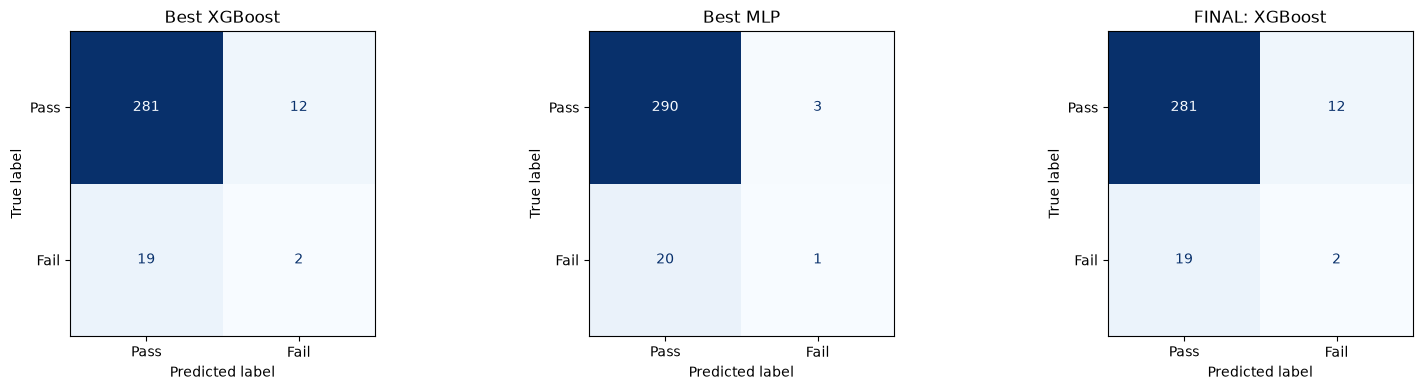

Final Test Macro-F1: 0.5310045772103108
Saved: SECOM_final_model.joblib / SECOM_final_test_results.csv


In [13]:
# FINAL TEST EVALUATION — DO NOT MODIFY
assert "_final_test_evaluated" not in globals(), "Test already evaluated in this session."
X_test, y_test = X.iloc[test_idx].copy(), y.iloc[test_idx].copy()
final_prob = predict_candidate(final_bundle, X_test)
final_cases = [("All-pass", np.zeros(len(y_test)), 0.5)]
for family, candidate in frozen_baselines.items():
    final_cases.append((f"{family} baseline @0.5", predict_candidate(candidate, X_test), 0.5))
for family, candidate in frozen_by_family.items():
    final_cases.append((f"Best {family} (validation-selected)",
        predict_candidate(candidate, X_test), candidate["threshold"]))
final_cases += [
    ("Selected final model @0.5", final_prob, 0.5),
    (f"FINAL: {final_bundle['family']} + validation threshold", final_prob, final_bundle["threshold"]),
]
test_results = pd.DataFrame([
    {"Model": name, "Threshold": t, **evaluate_scores(y_test, prob, t)}
    for name, prob, t in final_cases
]).set_index("Model")
_final_test_evaluated = True
display(y_test.value_counts().sort_index().rename("Test class count").to_frame())
display(test_results.round(4))
final_predictions = (final_prob >= final_bundle["threshold"]).astype(int)
print(classification_report(y_test, final_predictions, labels=[0, 1],
                            target_names=["Pass", "Fail"], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, case in zip(axes, [final_cases[3], final_cases[4], final_cases[-1]]):
    name, prob, t = case
    ConfusionMatrixDisplay.from_predictions(y_test, (prob >= t).astype(int),
        labels=[0, 1], display_labels=["Pass", "Fail"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(" (validation-selected)", "").replace(" + validation threshold", ""))
plt.tight_layout()
plt.show()
checkpoint = {
    "model": final_bundle["model"], "family": final_bundle["family"],
    "best_epoch": final_bundle.get("best_epoch"), "preprocessing": final_bundle["preprocessing"],
    "threshold": final_bundle["threshold"], "parameters": final_bundle["params"],
    "experiment": final_bundle["name"], "validation_macro_f1": final_bundle["selection_score"],
    "split_seed": SPLIT_SEED, "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx,
    "label_mapping": {-1: 0, 1: 1}, "test_results": test_results,
    "versions": {"numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "torch": torch.__version__},
}
joblib.dump(checkpoint, "SECOM_final_model.joblib")
test_results.to_csv("SECOM_final_test_results.csv")
print("Final Test Macro-F1:", test_results.iloc[-1][MAIN_METRIC])
print("Saved: SECOM_final_model.joblib / SECOM_final_test_results.csv")

## Results Report [100 points]

### 1. 모델·코드 개요

본 모델은 SECOM의 센서 측정값을 이용해 반도체 생산 샘플을 정상과 불량으로 분류한다. 전체 1,567건에는 센서 590개의 값이 있으며 일부 값은 비어 있다. 타임스탬프는 입력에서 제외하였다. 과제에서 지정한 층화 분할(seed 42)에 따라 Train 1,096건, Validation 157건, Test 314건을 사용하였다. 각 집합의 불량은 73건, 10건, 21건이다. 원래 라벨 −1과 +1은 각각 정상(0)과 불량(1)으로 변환하였다.

제출 코드에서는 **가중 Focal Loss를 적용한 XGBoost를 최종 모델로 사용하였다.** 성능을 비교하기 위해 기본 XGBoost와 기본 PyTorch MLP도 학습하였다. 기본 XGBoost는 트리를 하나씩 더해 앞선 트리들의 오차를 줄이고, 센서값이 비어 있을 때 어느 쪽으로 분기할지도 학습한다.

기본 MLP에 넣을 센서값 중 비어 있는 항목은 Train에서 구한 해당 센서의 중앙값으로 채웠다. 그다음 결측값을 채운 Train에서 센서별 평균과 표준편차를 구하였다. 각 센서값에서 해당 평균을 빼고 표준편차로 나누어 표준화하였다. 표준화한 센서값은 폭이 각각 128과 64인 두 은닉층을 거친다. 각 은닉층에서 ReLU와 dropout을 적용하고, 마지막 층의 출력에 sigmoid를 적용해 불량 점수를 구한다. 학습 손실로는 이진 교차 엔트로피(BCE)를 사용하였다.

최종 모델인 Focal XGBoost는 Train에서 값이 일정하거나 관측값이 하나도 없는 센서를 제외하였다. 남은 센서의 빈 값은 해당 센서의 Train 중앙값으로 채웠다. 그다음 두 센서의 Pearson 상관계수 절댓값이 0.85 이상이면 하나만 남겨 중복을 줄였다.

센서를 고르기 위해 Train의 정상과 불량에서 각각 중복을 허용해 표본을 다시 뽑았다(Bootstrap). 다시 뽑은 자료에서 센서별로 정상 집단과 불량 집단의 값이 얼마나 다른지 F 통계량으로 비교하였다. 이 과정을 20회 반복해 상위권에 자주 오른 센서 50개를 골랐다.

선택한 센서값 50개를 표준화한 뒤 주성분 분석(PCA)을 적용하였다. PCA는 여러 센서값을 조합해 센서들이 함께 변하는 양상을 보여 주는 새 값 8개를 만들었다. 센서마다 원래 값이 비어 있으면 1, 측정값이 있으면 0을 부여했다. 이 결측 표시 값 50개와 PCA로 얻은 값 8개를 합쳐 총 58개의 특징을 트리에 입력하였다. 부트스트랩은 센서 50개를 고를 때만 사용하고, 최종 트리를 학습할 때는 중복 추출을 하지 않은 원래의 Train 표본(1,096건)을 사용하였다.

최종 Focal XGBoost는 학습률 0.05, 최대 깊이 6, 학습 시드 24142로 트리 300개를 학습하였다. 학습 손실로는 가중 Focal Loss를 사용하였다. 정답 클래스의 예측 확률을 $p_t$라고 할 때, 교차 엔트로피에 $(1-p_t)^{0.5}$를 곱해 이미 잘 분류한 사례의 기여를 줄였다. 정상과 불량에는 같은 Focal 지수 0.5를 썼고, 불량의 가중치는 정상의 약 14.78배로 주었다. 학습에 쓰는 가중치는 평균이 1이 되도록 조정하였다. XGBoost는 손실 함수의 1차 미분(기울기)과 2차 미분(곡률, Hessian)을 이용해 트리를 학습한다. Focal Loss의 실제 2차 미분값은 음수가 될 수 있어, 트리 분할이 불안정해지는 것을 막기 위해 코드에서는 항상 양수가 보장되는 상한 근사식(Upper bound)을 사용하였다.

모델은 불량 점수가 임계값 이상이면 불량으로 판정한다. 최종 모델과 임계값을 선택할 때는 정상과 불량의 F1을 같은 비중으로 평균한 **Validation Macro-F1**을 기준으로 삼았으며, 임계값에 따른 검출 특성을 확인하기 위해 불량 정밀도·재현율을, 임계값과 무관한 순위 품질을 확인하기 위해 AP(Average Precision)를 함께 살폈다.

### 2. 모델 탐색 과정

#### History Overview

최종 모델에 도달하기까지 팀원들과 수행한 선행 탐색 실험(사전학습, 손실함수 변형, 파생변수 생성 등) 결과를 본 절에 요약하였다. 기본 모델이 불량을 얼마나 찾아내는지 확인한 뒤 임계값과 불량 가중치를 조정하였고, 이어 MLP의 학습 방법과 XGBoost에 넣는 센서 정보를 바꾸어 실제 불량이 더 높은 점수를 받는지 살폈다.

#### 기본 모델의 판정과 한계

Validation 157건을 모두 정상으로 예측하면 정확도는 93.63%다. 불량 F1은 0이고 정상 F1은 0.9671이므로 Macro-F1은 0.4836이다. 임계값 0.5에서 기본 XGBoost는 Validation 157건을 전부 정상으로 판정해 실제 불량 10건을 모두 놓쳤다. 기본 MLP는 임계값 0.5에서 불량 3건을 검출하고 정상 2건을 불량으로 판정하였다. 이때 Macro-F1은 0.68495였다.

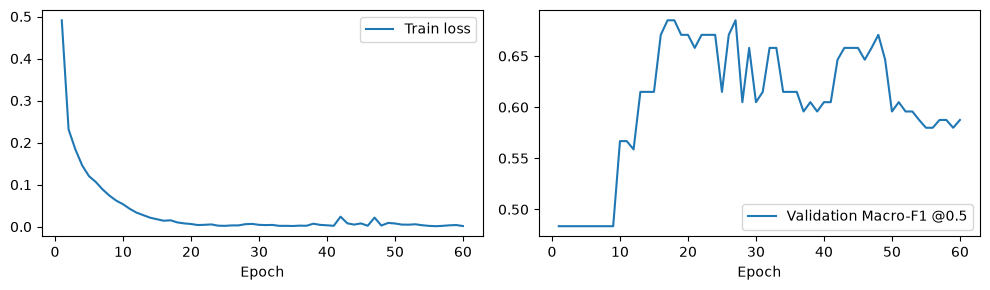

*그림 1. 기본 MLP의 Train 손실과 Validation Macro-F1. 왼쪽은 epoch별 BCE 평균이며, 오른쪽은 매 epoch에서 임계값 0.5로 계산한 점수다.*

기본 MLP의 Train 손실은 초반에 빠르게 줄었고 20 epoch 부근부터 낮은 수준에 머물렀다. 그 뒤에도 Validation 점수는 오르내렸다. 60 epoch까지 학습한 모델 중 Validation Macro-F1이 처음 최고점에 도달한 17 epoch의 모델을 평가에 사용하였다.

기본 XGBoost의 AP는 0.2670이었다. 모든 샘플에 같은 불량 점수를 주었을 때의 AP는 0.0637이었다. 실제 불량 가운데 기본 XGBoost가 높은 점수를 준 샘플이 있었으므로 임계값을 낮춰 보았다. 기본 XGBoost를 별도로 학습한 실험에서 임계값만 0.5에서 0.209로 낮추자 불량 3건을 검출하고 정상 6건을 불량으로 판정하였다. Macro-F1은 0.4836에서 0.6359로 올랐다.

판정 임계값을 0.5로 두고 불량의 학습 가중치만 높여 보았다. 불량 가중치를 14.01로 높이자 학습 시드 42에서 XGBoost의 Macro-F1은 0.6580으로 올랐다. MLP도 불량 검출이 3건에서 4건으로 늘었지만 정상 오탐은 2건에서 4건으로 늘었다. 학습 시드 0~4에서는 기본 MLP의 평균 Macro-F1이 0.685, 불량 가중치를 높인 MLP는 0.674였다.

#### MLP의 순위 손실과 사전학습

MLP에서는 같은 배치의 정상과 불량을 짝지어 점수를 비교하였다. 불량 점수가 정상 점수보다 낮을수록 벌점이 커지도록 하고, 이 값을 순위 손실(Ranking loss)로 BCE에 더하였다. 정상 샘플을 모두 순위 손실 계산에 쓴 모델은 6 epoch에서 Validation Macro-F1이 0.75496이었다. 점수가 높은 정상 샘플 절반만 사용한 모델은 같은 시점에 불량을 한 건 더 잡고 정상 오탐을 한 건 줄여 0.82497을 기록하였다. 그러나 나머지 조건을 맞추고 순위 손실 계산에 정상 샘플 전체를 쓰는 조건과 점수 상위 25%, 50%, 75%만 쓰는 조건을 689쌍에서 비교했을 때 평균 개선 폭은 약 0.0008에 그쳤다. 0.82497을 기록한 모델도 시드를 바꾸어 여섯 번 학습한 뒤 처음 정한 임계값을 적용하자 평균 Macro-F1이 0.66457로 낮아졌다.

순위 손실을 사용한 MLP가 어떤 불량을 찾아냈는지 알아보기 위해 Validation Macro-F1이 같은 XGBoost와 비교하였다. 이 XGBoost는 판정할 샘플이 Train의 가까운 정상 샘플과 불량 샘플에서 각각 얼마나 떨어져 있는지 계산해 입력에 사용하였다. 두 모델은 Validation의 실제 불량 10건 중 각각 5건을 찾아냈고 정상 오탐은 없었다. 두 모델이 공통으로 찾아낸 불량은 3건이었다. 실제 불량인 235번 샘플은 MLP만, 1227번 샘플은 XGBoost만 불량으로 판정하였다.

일부 센서값이 달라져도 같은 샘플의 정보를 비슷하게 표현하도록 MLP를 사전학습하는 방법도 비교하였다. SCARF는 같은 샘플을 그대로 넣었을 때와 일부 센서값을 바꾸어 넣었을 때 모델이 비슷한 표현을 얻도록 학습하는 대조 사전학습 방법이다. 센서값이 비어 있었는지를 나타내는 값까지 포함해 449개 값을 폭 24와 12의 두 은닉층에 입력하였다. SCARF로 사전학습을 마친 뒤 일반 BCE를 써서 정상과 불량을 구분하도록 학습하였다.

SCARF 사전학습과 일반 BCE를 사용한 모델을 다시 학습하여 Validation에서 14 epoch의 모델과 임계값 0.350886을 골랐다. Validation Macro-F1은 **0.71914**였으며, 오탐 없이 불량 10건 중 3건을 검출하였다. 같은 모델과 임계값을 Test에 적용하자 Macro-F1은 **0.51853**이었다. 불량 21건 중 1건을 검출하고 정상 4건을 불량으로 판정하였다. AP는 Validation의 0.4605에서 Test의 0.1197로 낮아졌다.

초기 MLP 탐색에서는 같은 Validation에서 모델 설정과 학습 시점, 임계값을 반복해서 골랐다. SCARF 사전학습과 일반 BCE를 사용한 모델을 Train 내부에서 층화 5-fold로 다시 검증하였다. Train을 불량 비율이 비슷한 다섯 부분으로 나누고, 매번 한 부분을 평가용으로 떼어 두었다. 나머지 데이터에서 따로 나눈 내부 검증 데이터로 학습 시점과 임계값을 결정하였다. 학습 시점과 임계값을 고른 내부 검증의 평균 Macro-F1은 0.64487이었다. 따로 떼어 둔 데이터로 평가했을 때 평균은 **0.54552**였다. 다섯 번의 평가 결과를 합하면 불량 73건 중 15건을 검출하였으며, 평가별 AP의 평균은 0.15040이었다. 같은 검증 자료에서 좋은 조건을 반복해서 고르는 과정에서 검증 표본에 과적합했을 가능성이 있다. 각 반복의 학습에 사용한 불량이 46~47건으로 줄어든 점도 성능 차이에 영향을 주었을 수 있다.

#### XGBoost의 센서 특징과 Focal Loss

임계값을 낮춘 실험에서는 정상 샘플에도 불량 판정이 늘었다. 실제 불량에 더 높은 점수를 줄 수 있도록 XGBoost에 넣는 센서 정보를 바꾸어 보았다. 센서 두 개의 값이 각각 흔한 범위에 들어도 두 값의 관계는 평소와 다를 수 있다. 한 센서값으로 다른 센서값을 예측하고, 예측값과 실제 값의 차이인 잔차(Residual)를 입력에 추가하였다. 학습 시드와 최대 트리 수를 동일하게 맞춘 689개의 실험 쌍을 비교한 결과, 잔차를 넣은 모델의 Validation Macro-F1이 평균 0.01294 높았다. 잔차를 계속 사용하면서 트리 깊이를 2에서 4로 늘렸을 때는 점수가 평균 약 0.0118 낮아졌다.

이처럼 파생 특징의 효과를 확인한 뒤, 본격적인 최적화를 위해 기존 탐색에서 Validation 점수가 높았던 상위 모델(센서 20개 사용, **M1**)을 기준으로 단계적 개선(**M1~M5**)을 진행하였다. 같은 센서를 쓰면서 불량 가중치와 트리 분할 조건을 바꾸자(**M2**) 불량은 여전히 5건을 검출했고, 정상 오탐은 1건에서 0건으로 줄었다. 이어 각 샘플의 센서값이 정상 샘플에서 관측된 값과 얼마나 다른지를 계산해 입력에 더하고 트리 설정도 바꾸었다(**M3**). 앞서 불량 가중치와 분할 조건을 바꾼 모델(**M2**)과 Validation 157건의 판정이 모두 같았고, AP는 0.53766에서 0.55632로 올랐다.

| 모델 | XGBoost 후보의 주요 설정 | Validation Macro-F1 | Validation AP | 불량 검출 / 정상 오탐 |
|:---:|---|---:|---:|---:|
| **M1** | 원 센서 20개와 가중 BCE | 0.80243 | 0.50058 | 5 / 1 |
| **M2** | 원 센서 20개 유지, 불량 가중치와 분할 조건 조정 | 0.82497 | 0.53766 | 5 / 0 |
| **M3** | 정상 상태에서 벗어난 정도를 나타내는 특징 추가 | 0.82497 | 0.55632 | 5 / 0 |
| **M4** | PCA로 구한 값 8개와 측정 여부, 정상·불량에 서로 다른 Focal 지수 | 0.86829 | 0.64290 | 6 / 0 |
| **M5** | 같은 입력, 정상·불량에 Focal 지수 0.5, 트리 300개 (`focal:19811:300`) | **0.86829** | **0.64790** | 6 / 0 |

이후 센서값을 PCA로 계산한 값 8개로 바꾸고, 센서마다 값이 비어 있었는지도 함께 입력하였다(**M4**). 이 입력을 쓰면서 정상과 불량에 서로 다른 Focal 지수를 적용한 실험에서는 정상 오탐 없이 불량을 6건 검출하였다. 입력에 쓸 센서와 트리 설정도 함께 바꾼 결과다.

다음 실험(**M5**)에서는 입력을 그대로 두고 정상과 불량에 모두 Focal 지수 0.5를 썼다. 트리 수는 100개에서 300개로 늘렸고, 각 트리가 내는 점수가 지나치게 커지지 않도록 벌점을 높였다. 불량 검출과 정상 오탐 건수는 같았고 AP는 0.64290에서 0.64790으로 올랐다. Focal 지수와 트리 설정을 함께 바꾸었으므로, 둘의 효과를 따로 판단하기는 어렵다.

#### 최종 모델의 설정과 선택

최종 모델은 **Focal XGBoost** (`M5`, `focal:19811:300`)이다. 센서값 50개를 PCA로 8개 값으로 줄이고, 센서마다 값이 비어 있었는지를 나타내는 50개 값을 함께 입력하였다. 정상과 불량에 같은 Focal 지수 0.5를 쓰고 트리 300개를 학습하였다. 기본 XGBoost, 기본 MLP와 비교했을 때 Validation Macro-F1이 **0.86829**로 가장 높았다. Test에는 Validation에서 정한 임계값 0.685169를 적용하였다.

### 3. 결과 정리

#### 최종 모델의 평가 결과

그림 2는 최종 Focal XGBoost와 기본 MLP의 Validation 혼동행렬이다. 최종 모델은 기본 MLP보다 불량을 세 건 더 검출하고 정상 오탐을 두 건 줄였다.

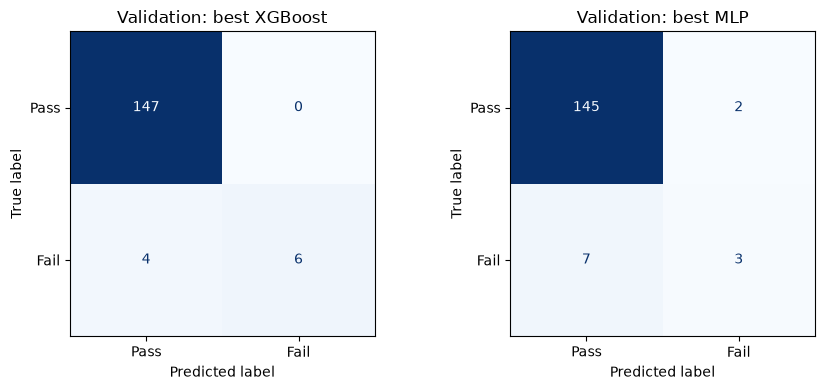

*그림 2. 왼쪽은 임계값 0.685169의 최종 Focal XGBoost, 오른쪽은 임계값 0.5의 기본 MLP다. 각 혼동행렬의 오른쪽 열은 불량으로 판정한 건수다.*

최종 Focal XGBoost에 기본 임계값 0.5와 Validation에서 선택한 임계값 0.685169를 각각 적용하였다. 표의 TN과 TP는 각각 정상과 불량을 맞힌 건수이고, FP는 정상 오탐, FN은 불량 누락이다.

| 평가 데이터 | 임계값 | Macro-F1 | Accuracy | Balanced Accuracy | 불량 정밀도 / 재현율 / F1 | AP | TN / FP / FN / TP |
|---|---:|---:|---:|---:|---:|---:|---:|
| Validation | 0.5 | 0.62128 | 0.82803 | 0.76837 | 0.22581 / 0.70000 / 0.34146 | 0.64790 | 123 / 24 / 3 / 7 |
| Validation | 0.685169 | **0.86829** | 0.97452 | 0.80000 | 1.00000 / 0.60000 / 0.75000 | 0.64790 | 147 / 0 / 4 / 6 |
| Test | 0.5 | 0.57395 | 0.83758 | 0.62563 | 0.17391 / 0.38095 / 0.23881 | 0.13967 | 255 / 38 / 13 / 8 |
| Test | 0.685169 | **0.53100** | 0.90127 | 0.52714 | 0.14286 / 0.09524 / 0.11429 | 0.13967 | 281 / 12 / 19 / 2 |

Validation에서 임계값을 0.5에서 0.685169로 높이자 정상 오탐 24건이 사라졌고 불량 검출은 7건에서 6건으로 줄었다. Test에서 임계값 0.685169를 적용하면 0.5를 적용했을 때보다 정상 오탐이 38건에서 12건으로, 불량 검출이 8건에서 2건으로 줄었다. 최종 Test Macro-F1은 Validation에서 확정한 임계값 0.685169에서 **0.53100**이었다.

#### 불량 검출 실패와 일반화

최종 모델은 Test에서 불량 21건 중 19건을 놓쳤다. 모델이 불량으로 판정한 14건 중 12건은 실제로 정상이었다. 불량 누락은 불량품이 후속 공정으로 넘어가게 할 수 있다. 정상 오탐이 많으면 추가 검사나 정상 제품의 폐기가 늘어날 수 있다.

최종 Focal XGBoost의 AP는 Validation에서 0.64790이었으나 Test에서 0.13967로 낮아졌다. Test에서는 기본 XGBoost의 AP인 0.18752보다도 낮았다. 최종 모델의 점수를 높은 순서로 살폈을 때 실제 불량이 Validation만큼 앞에 나오지 않았다. 최종 모델의 Macro-F1은 기본 MLP보다 Validation에서 0.18334 높았다. Test에서는 두 모델의 차이가 0.01008로 줄었다. Test에서 최종 모델은 기본 MLP보다 불량을 한 건 더 검출하였고, 정상 오탐은 3건에서 12건으로 늘었다.

다른 설정에서도 Validation 성능이 새 표본에서 유지되는지 살폈다. 상관이 높은 센서를 줄이고 F 통계량으로 센서 20개를 고른 XGBoost(R20, #578)는 고정 Validation에서 0.8024였으나, Train을 여러 번 나누어 평가한 평균은 0.5362였다. 불량 가중치와 임계값을 조정한 XGBoost의 Test Macro-F1은 0.5799였고, 불량 21건 중 3건을 검출하였다. 불량 샘플끼리 비슷한 표현을 얻도록 사전학습한 MLP는 Train 내부 교차검증에서 평균 Macro-F1이 0.60856이었다. 같은 사전학습 방법을 사용한 모델의 Test Macro-F1은 0.5007이었고 불량 한 건을 검출하였다.

Validation에서는 불량 한 건을 더 검출하면 재현율이 10%p 오른다. 같은 불량 10건을 놓고 여러 모델 설정과 학습 시드, 학습 시점, 임계값을 반복해서 비교하면 그 검증 표본에 잘 맞는 조합이 남기 쉽다.


### References

1. [UCI SECOM dataset](https://archive.ics.uci.edu/dataset/179/secom) — original data and label documentation.
2. [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html) — tree settings, binary objective, and `scale_pos_weight`.
3. [scikit-learn F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) — class-wise and macro averaging.
4. [scikit-learn Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
5. [scikit-learn: Data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
